# Unbiased random walk and ensemble moments

A discrete random walk provides the simplest derivation of normal
diffusion. The notebook compares irregular individual paths with the smooth
ensemble prediction $\langle X^2(t)\rangle=2Dt$.

The numerical calculation, verification, and plotting are kept in separate
cells. Plotting cells only read stored results and do not advance the model or
generate new random samples.


In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "README.md").exists()
    and (
        (path / "main.tex").exists()
        or (path / "lecture-notes" / "main.tex").exists()
    )
)
if ROOT.name == "dlsu_PHY627M_GS1":
    OUTPUT = ROOT / "figures" / "24_brownian-motion-diffusion"
elif ROOT.name == "dlsu_SEMPHY01":
    OUTPUT = ROOT / "lecture-notes" / "figures" / "08_brownian-motion-diffusion"
else:
    raise RuntimeError(f"unsupported course repository: {ROOT}")
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180})


## Model and parameters

Each increment is $\Delta X_s=\pm\ell$ with equal probability. Independent
increments have zero mean and variance $\ell^2$. The simulation stores a small
set of paths but evaluates ensemble moments using all walkers.


In [2]:
rng = np.random.default_rng(62701)
walker_count = 40_000
step_count = 400
shown_walker_count = 12
step_length = 1.0
step_time = 0.25
diffusivity = step_length**2 / (2.0 * step_time)

time = step_time * np.arange(step_count + 1)
position = np.zeros(walker_count)
shown_paths = np.zeros((step_count + 1, shown_walker_count))
mean_position = np.zeros(step_count + 1)
mean_square_displacement = np.zeros(step_count + 1)

for step in range(1, step_count + 1):
    direction = 2 * rng.integers(0, 2, size=walker_count) - 1
    position += step_length * direction
    shown_paths[step] = position[:shown_walker_count]
    mean_position[step] = np.mean(position)
    mean_square_displacement[step] = np.mean(position**2)

predicted_msd = 2.0 * diffusivity * time


## Verification

The fitted MSD slope determines an independent numerical estimate of $D$.
The ensemble mean should remain small relative to the diffusive width.


In [3]:
slope = np.polyfit(time[1:], mean_square_displacement[1:], 1)[0]
fitted_diffusivity = slope / 2.0
final_width = np.sqrt(mean_square_displacement[-1])

assert abs(mean_position[-1]) < 0.02 * final_width
assert np.isclose(fitted_diffusivity, diffusivity, rtol=0.02)
print(f"predicted D = {diffusivity:.6f}")
print(f"fitted D    = {fitted_diffusivity:.6f}")
print(f"final mean / rms width = {mean_position[-1] / final_width:.4f}")


predicted D = 2.000000
fitted D    = 2.019448
final mean / rms width = 0.0005


## Instructive plot

The left panel shows that individual paths remain irregular. The center panel
shows cancellation in the ensemble mean. The right panel tests the quantitative
diffusion law.


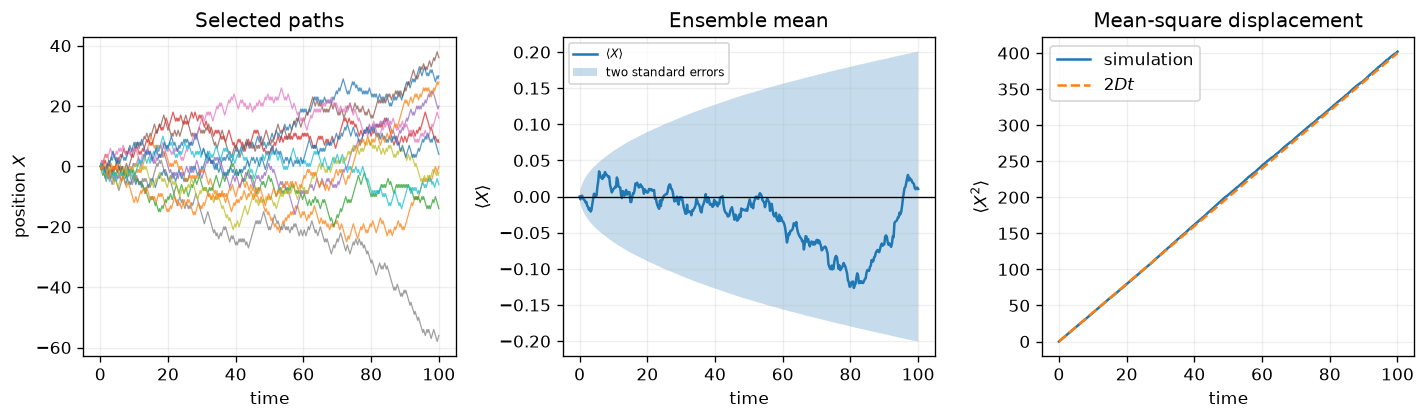

wrote lecture-notes/figures/08_brownian-motion-diffusion/01-unbiased-random-walk.pdf


In [4]:
figure, axes = plt.subplots(1, 3, figsize=(12.0, 3.6))

axes[0].plot(time, shown_paths, linewidth=0.75, alpha=0.75)
axes[0].set(title="Selected paths", xlabel="time", ylabel=r"position $X$")

standard_error = np.sqrt(mean_square_displacement / walker_count)
axes[1].plot(time, mean_position, label=r"$\langle X\rangle$")
axes[1].fill_between(
    time,
    -2.0 * standard_error,
    2.0 * standard_error,
    alpha=0.25,
    label="two standard errors",
)
axes[1].axhline(0.0, color="black", linewidth=0.8)
axes[1].set(title="Ensemble mean", xlabel="time", ylabel=r"$\langle X\rangle$")
axes[1].legend(fontsize=7)

axes[2].plot(time, mean_square_displacement, label="simulation")
axes[2].plot(time, predicted_msd, "--", label=r"$2Dt$")
axes[2].set(
    title="Mean-square displacement",
    xlabel="time",
    ylabel=r"$\langle X^2\rangle$",
)
axes[2].legend()

for axis in axes:
    axis.grid(alpha=0.2)
figure.tight_layout()
output_path = OUTPUT / "01-unbiased-random-walk.pdf"
figure.savefig(
    output_path,
    bbox_inches="tight",
    metadata={"Creator": f"DLSU {ROOT.name.removeprefix('dlsu_')}", "CreationDate": None, "ModDate": None},
)
plt.show()
print(f"wrote {output_path.relative_to(ROOT)}")
